# Keratoconus detection from four corneal maps: cross-modal attention fusion

Four ResNet-50 encoders (anterior, axial, pachymetry, posterior maps) are fused with scaled cosine cross-attention. Trained on ORBSCAN (CornORB), then evaluated zero-shot on an independent Pentacam cohort. The decision threshold and temperature are fit on ORBSCAN validation only.

**Reproducibility.** GPU training is not bit-identical between runs, so the reported numbers come from released weights. If `keratoconus_released_weights.pt` is found (Kaggle input, working folder or next to this notebook) training is skipped and the same weights are evaluated.

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import random, re, shutil, zipfile, hashlib, copy, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss, recall_score)
from sklearn.calibration import calibration_curve
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, resnet50, ResNet18_Weights, ResNet50_Weights

SEED, IMG_SIZE, BATCH_SIZE, EPOCHS, NUM_WORKERS = 42, 300, 4, 30, 2
MODALITIES = ['anterior', 'axial', 'pachymetry', 'posterior']
CLASS_NAMES = ['Normal', 'Keratoconus']
N_BOOTSTRAP = 2000
BACKBONE = 'resnet50'
RESNETS = {
    'resnet50': (resnet50, ResNet50_Weights.IMAGENET1K_V1),
    'resnet18': (resnet18, ResNet18_Weights.IMAGENET1K_V1),
}
LABEL_SMOOTHING = 0.0
USE_TEMPERATURE_SCALING = True
TEMPERATURE = 1.0
MIN_SENSITIVITY = 0.95        # screening floor: validation sensitivity the operating point must reach
SPEC_TOL = 0.01               # ... then the threshold is centred among those within this of the best specificity
THRESHOLD_RULE = 'screening'  # 'screening' | 'plateau' | 'edge' (older rules, kept for comparison)
PLATEAU_TOL = 0.01            # used by 'plateau': Youden's J within this of its validation maximum

TOKEN_GRID = 7
FUSE_DIM = 256
N_HEADS = 2
ENCODER_LR = 1e-4
FUSION_LR = 1.5e-4
WARMUP_EPOCHS = 2
GRAD_CLIP_NORM = 1.0
MAX_ROLLBACKS = 3
EARLY_STOP_PATIENCE = 5
SELECT_BY = 'val_loss'        # checkpoint / early-stopping criterion: 'val_loss' or 'val_auc'
USE_EMA = True                # evaluate and keep an exponential moving average of the weights
EMA_DECAY = 0.99
CROSS_ATTN_DROPOUT = 0.15

WORK = Path('/kaggle/working')
CHECKPOINT = WORK / 'best_cross_attention_fusion_model.pt'
FIG_DIR = WORK / 'figures'
MAIN_MANIFEST_PATH = Path('/kaggle/input/datasets/nasiruddin66/cornorb/CornORB/manifest.csv')
EXTERNAL_MANIFEST_PATH = Path('/kaggle/input/datasets/nasiruddin66/cornorb/pentacam-external-validation/manifest.csv')

# released weights: if found, training is skipped and these exact weights are evaluated
RELEASED_WEIGHTS_NAME = 'keratoconus_released_weights.pt'
PRETRAINED_CHECKPOINT = None
if Path('/kaggle/input').exists() or (WORK / RELEASED_WEIGHTS_NAME).exists():
    hits = list(Path('/kaggle/input').rglob(RELEASED_WEIGHTS_NAME)) if Path('/kaggle/input').exists() else []
    hits += [p for p in (WORK / RELEASED_WEIGHTS_NAME, Path(RELEASED_WEIGHTS_NAME)) if p.is_file()]
    PRETRAINED_CHECKPOINT = str(hits[0]) if hits else None


def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


warnings.filterwarnings('ignore', category=UserWarning, module='torch')
warnings.filterwarnings('always', message='.*deterministic.*')   # but still tell us if a non-deterministic op slips in
set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEVICE.type == 'cuda', 'Enable a Kaggle GPU accelerator.'

# plotting style: one palette used everywhere (colour-blind safe)
C_INT, C_EXT = '#0072B2', '#D55E00'
C_CLASS = {0: '#009E73', 1: '#CC79A7'}
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'figure.constrained_layout.use': True,
    'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.labelsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
    'grid.linewidth': .6, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 1.8,
})
shutil.rmtree(FIG_DIR, ignore_errors=True)
FIG_DIR.mkdir(parents=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')
    fig.savefig(FIG_DIR / f'{name}.pdf')
    plt.show()


def tag(ax, letter):
    ax.text(-.14, 1.06, letter, transform=ax.transAxes, fontsize=12, fontweight='bold')


print('GPU:', torch.cuda.get_device_name(0))
print('Weights:', PRETRAINED_CHECKPOINT or 'none found, training from scratch')

GPU: Tesla T4
Weights: none found, training from scratch


In [2]:
def load_manifest(path):
    assert path.is_file(), f'File not found: {path}'
    root = path.parent
    d = pd.read_csv(path)
    d['label'] = d.label.astype(int)
    assert {'patient_id', 'eye', 'label', *[f'{m}_path' for m in MODALITIES]}.issubset(d.columns)
    assert set(d.label.unique()) <= {0, 1}
    for m in MODALITIES:
        assert d[f'{m}_path'].map(lambda p: (root / p).is_file()).all(), f'Missing {m} files in {root}'
    return d, root


df, ROOT = load_manifest(MAIN_MANIFEST_PATH)
external_df, EXTERNAL_ROOT = load_manifest(EXTERNAL_MANIFEST_PATH)

prefix = df['anterior_path'].map(lambda p: Path(p).stem.split('_')[0])
assert (prefix == df['patient_id'].astype(str)).all(), 'patient_id does not match the filename prefix'

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_i, test_i = next(outer.split(df, df.label, groups=df.patient_id))
trainval, test_df = df.iloc[trainval_i].reset_index(drop=True), df.iloc[test_i].reset_index(drop=True)
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
train_i, val_i = next(inner.split(trainval, trainval.label, groups=trainval.patient_id))
train_df, val_df = trainval.iloc[train_i].reset_index(drop=True), trainval.iloc[val_i].reset_index(drop=True)

splits = {'ORBSCAN train': train_df, 'ORBSCAN validation': val_df, 'ORBSCAN test': test_df, 'Pentacam external': external_df}
ids = [set(x.patient_id) for x in splits.values()][:3]
assert not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]), 'patient leakage between splits'

summary = pd.DataFrame([
    {'split': n, 'eyes': len(x), 'patients': x.patient_id.nunique(), 'normal': int((x.label == 0).sum()),
     'keratoconus': int((x.label == 1).sum()), 'keratoconus %': 100 * x.label.mean()}
    for n, x in splits.items()
])
display(summary.style.format({'keratoconus %': '{:.1f}'}).hide(axis='index'))
for n, x in list(splits.items())[:3]:
    x.to_csv(WORK / f"{n.split()[1]}_split.csv", index=False)

split,eyes,patients,normal,keratoconus,keratoconus %
ORBSCAN train,899,477,557,342,38.0
ORBSCAN validation,226,119,145,81,35.8
ORBSCAN test,282,148,184,98,34.8
Pentacam external,395,395,197,198,50.1


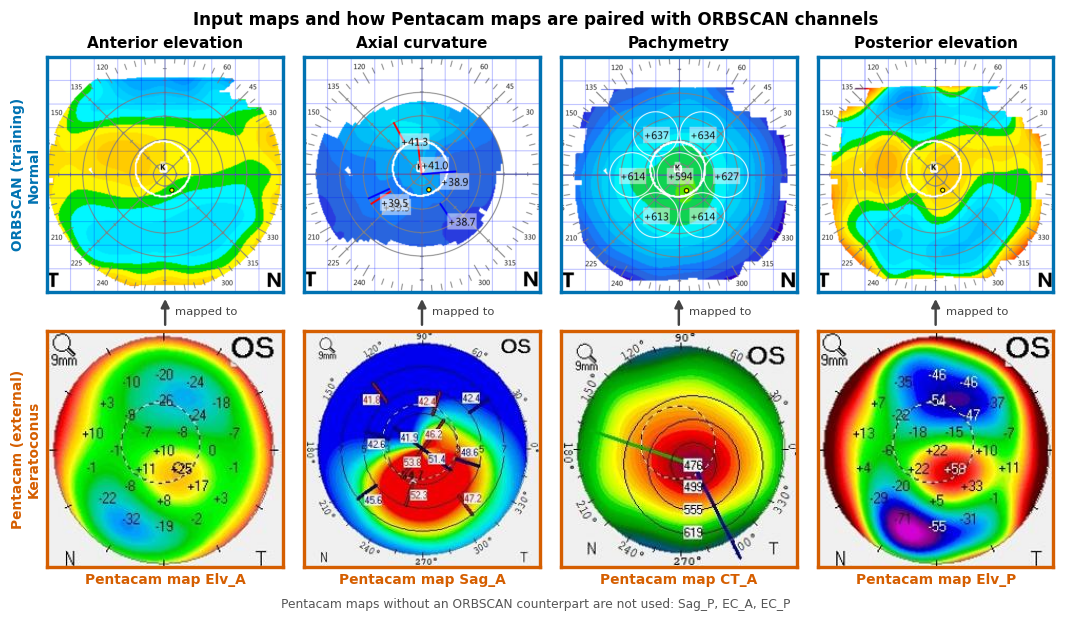

In [3]:
# how the two devices are paired: each Pentacam map feeds the ORBSCAN channel it clinically corresponds to
PAIRS = {'anterior': 'Elv_A', 'axial': 'Sag_A', 'pachymetry': 'CT_A', 'posterior': 'Elv_P'}
LABELS = {'anterior': 'Anterior elevation', 'axial': 'Axial curvature',
          'pachymetry': 'Pachymetry', 'posterior': 'Posterior elevation'}
NOT_USED = ['Sag_P', 'EC_A', 'EC_P']

ob = train_df.sample(1, random_state=SEED).iloc[0]
pc = external_df.sample(1, random_state=SEED).iloc[0]

fig, ax = plt.subplots(3, 4, figsize=(9.6, 5.3), gridspec_kw={'height_ratios': [1, .11, 1]})
fig.get_layout_engine().set(h_pad=.03, w_pad=.03, hspace=0, wspace=.02)
for j, m in enumerate(MODALITIES):
    for row, rec, root, colour in ((0, ob, ROOT, C_INT), (2, pc, EXTERNAL_ROOT, C_EXT)):
        a = ax[row, j]
        a.imshow(Image.open(root / rec[f'{m}_path']).convert('RGB'))
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        for s in a.spines.values():
            s.set_visible(True); s.set_edgecolor(colour); s.set_linewidth(2.2)
    ax[0, j].set_title(LABELS[m], fontweight='bold')
    ax[2, j].set_xlabel(f'Pentacam map {PAIRS[m]}', color=C_EXT, fontweight='bold')
    g = ax[1, j]
    g.axis('off')
    g.annotate('', xy=(.5, 1.0), xytext=(.5, 0.0), xycoords='axes fraction',
               arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#444', mutation_scale=11, shrinkA=0, shrinkB=0))
    g.text(.54, .5, 'mapped to', transform=g.transAxes, va='center', fontsize=7.5, color='#444')
ax[0, 0].set_ylabel(f'ORBSCAN (training)\n{CLASS_NAMES[ob.label]}', color=C_INT, fontweight='bold')
ax[2, 0].set_ylabel(f'Pentacam (external)\n{CLASS_NAMES[pc.label]}', color=C_EXT, fontweight='bold')
fig.suptitle('Input maps and how Pentacam maps are paired with ORBSCAN channels', fontsize=11, fontweight='bold')
fig.text(.5, -.03, f"Pentacam maps without an ORBSCAN counterpart are not used: {', '.join(NOT_USED)}",
         ha='center', fontsize=8, color='#555')
save(fig, 'fig1_data_and_modality_mapping')

In [4]:
normalise = transforms.Normalize([.485, .456, .406], [.229, .224, .225])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(3, translate=(.02, .02), scale=(.98, 1.02)),
    transforms.ToTensor(),
    normalise,
])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), normalise])


class MapDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.f, self.root, self.tf = frame.reset_index(drop=True), Path(root), transform

    def __len__(self):
        return len(self.f)

    def __getitem__(self, i):
        r = self.f.iloc[i]
        maps = []
        for m in MODALITIES:
            with Image.open(self.root / r[f'{m}_path']) as im:
                maps.append(self.tf(im.convert('RGB')))
        return torch.stack(maps), torch.tensor(r.label, dtype=torch.float32), r.patient_id


def seed_worker(_):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s); random.seed(s)


gen = torch.Generator()
gen.manual_seed(SEED)
kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True,
          worker_init_fn=seed_worker)
train_loader = DataLoader(MapDataset(train_df, ROOT, train_tf), shuffle=True, generator=gen, **kw)
val_loader = DataLoader(MapDataset(val_df, ROOT, eval_tf), shuffle=False, **kw)
test_loader = DataLoader(MapDataset(test_df, ROOT, eval_tf), shuffle=False, **kw)
external_loader = DataLoader(MapDataset(external_df, EXTERNAL_ROOT, eval_tf), shuffle=False, **kw)


class DetAdaptivePool(nn.Module):
    """Adaptive average pooling written as two matrix products: same result as nn.AdaptiveAvgPool2d,
    but its backward pass is deterministic on GPU (the built-in one is not)."""

    def __init__(self, out):
        super().__init__()
        self.out, self._cache = out, {}

    def _matrix(self, n, device):
        key = (n, str(device))
        if key not in self._cache:
            m = torch.zeros(self.out, n)
            for i in range(self.out):
                s, e = (i * n) // self.out, -(-((i + 1) * n) // self.out)
                m[i, s:e] = 1.0 / (e - s)
            self._cache[key] = m.to(device)
        return self._cache[key]

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            return self._matrix(x.shape[-2], x.device) @ x @ self._matrix(x.shape[-1], x.device).T


class ResNetEncoder(nn.Module):
    def __init__(self, name=BACKBONE):
        super().__init__()
        ctor, weights = RESNETS[name]
        try:
            net = ctor(weights=weights)
        except Exception as e:
            print('Pretrained weights unavailable:', e)
            net = ctor(weights=None)
        self.features = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool,
                                      net.layer1, net.layer2, net.layer3, net.layer4)
        self.out_channels = net.fc.in_features
        self.pool = DetAdaptivePool(TOKEN_GRID)

    def forward(self, x):
        return self.pool(self.features(x))


class ScaledCosineAttention(nn.Module):
    """Cross-attention on L2-normalised queries and keys with a learned, capped temperature (Swin V2)."""

    def __init__(self, dim, n_heads, dropout=0.0):
        super().__init__()
        assert dim % n_heads == 0
        self.n_heads, self.head_dim = n_heads, dim // n_heads
        self.q_proj, self.k_proj = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.v_proj, self.out_proj = nn.Linear(dim, dim), nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.logit_scale = nn.Parameter(torch.full((n_heads, 1, 1), 2.302585092994046))  # log(10)

    def forward(self, query, context):
        b, nq, d = query.shape
        nk = context.shape[1]
        q = self.q_proj(query).view(b, nq, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(context).view(b, nk, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(context).view(b, nk, self.n_heads, self.head_dim).transpose(1, 2)
        q, k = F.normalize(q, dim=-1), F.normalize(k, dim=-1)
        scale = torch.clamp(self.logit_scale, max=4.605170185988092).exp()  # capped at 100
        attn = self.dropout(((q @ k.transpose(-2, -1)) * scale).softmax(dim=-1))
        return self.out_proj((attn @ v).transpose(1, 2).reshape(b, nq, d))


class CrossModalAttention(nn.Module):
    """Tokens of modality i attend to the concatenated tokens of the other three modalities."""

    def __init__(self, dim=FUSE_DIM, n_heads=N_HEADS, n_modalities=4, dropout=CROSS_ATTN_DROPOUT):
        super().__init__()
        self.n = n_modalities
        self.attn = nn.ModuleList([ScaledCosineAttention(dim, n_heads, dropout) for _ in range(self.n)])
        self.norm1 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.n)])
        self.ff = nn.ModuleList([nn.Sequential(nn.Linear(dim, dim * 2), nn.GELU(), nn.Dropout(dropout),
                                               nn.Linear(dim * 2, dim)) for _ in range(self.n)])
        self.norm2 = nn.ModuleList([nn.LayerNorm(dim) for _ in range(self.n)])

    def forward(self, tokens):
        out = []
        for i in range(self.n):
            context = torch.cat([tokens[j] for j in range(self.n) if j != i], dim=1)
            x = self.norm1[i](tokens[i] + self.attn[i](tokens[i], context))
            out.append(self.norm2[i](x + self.ff[i](x)))
        return out


class FourEncoderCrossAttentionFusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.ModuleList([ResNetEncoder() for _ in MODALITIES])
        c = self.enc[0].out_channels
        self.token_proj = nn.ModuleList([nn.Sequential(nn.LayerNorm(c), nn.Linear(c, FUSE_DIM)) for _ in MODALITIES])
        self.modality_embed = nn.Parameter(torch.randn(len(MODALITIES), 1, 1, FUSE_DIM) * 0.02)
        self.cross_attn = CrossModalAttention(dim=FUSE_DIM, n_heads=N_HEADS, n_modalities=len(MODALITIES))
        self.gate = nn.Sequential(nn.LayerNorm(FUSE_DIM), nn.Linear(FUSE_DIM, 128), nn.GELU(), nn.Linear(128, 1))
        self.head = nn.Sequential(nn.LayerNorm(FUSE_DIM * 2), nn.Linear(FUSE_DIM * 2, 256), nn.GELU(),
                                  nn.Dropout(.35), nn.Linear(256, 1))

    def forward(self, x):
        tokens = []
        for i, (e, p) in enumerate(zip(self.enc, self.token_proj)):
            fmap = e(x[:, i])
            b, c, h, w = fmap.shape
            tokens.append(p(fmap.flatten(2).transpose(1, 2)) + self.modality_embed[i].expand(b, h * w, -1))
        attended = self.cross_attn(tokens)
        pooled = torch.stack([t.mean(dim=1) for t in attended], dim=1)
        a = torch.softmax(self.gate(pooled).squeeze(-1), 1)          # per-modality weight
        fused = torch.cat([(pooled * a.unsqueeze(-1)).sum(1), pooled.max(1).values], 1)
        return self.head(fused).squeeze(1), a


set_seed()
model = FourEncoderCrossAttentionFusion().to(DEVICE)
print(f'{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters')


@torch.no_grad()
def predict(loader, loss_fn=None, net=None):
    net = model if net is None else net
    net.eval()
    y, p, a, losses = [], [], [], []
    for x, t, _ in loader:
        x, t = x.to(DEVICE, non_blocking=True), t.to(DEVICE, non_blocking=True)
        logit, att = net(x)
        if loss_fn is not None:
            losses.append(loss_fn(logit, t).item() * t.size(0))
        y.extend(t.cpu().numpy())
        p.extend(torch.sigmoid(logit.float() / TEMPERATURE).cpu().numpy())
        a.append(att.cpu().numpy())
    y, p = np.asarray(y, int), np.asarray(p)
    if loss_fn is not None:
        return y, p, np.concatenate(a), sum(losses) / len(y)
    return y, p, np.concatenate(a)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 214MB/s]


98.4M parameters


In [5]:
pos = torch.tensor([(train_df.label == 0).sum() / (train_df.label == 1).sum()], device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos)
fusion_params = (list(model.token_proj.parameters()) + [model.modality_embed] + list(model.cross_attn.parameters())
                 + list(model.gate.parameters()) + list(model.head.parameters()))
opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': ENCODER_LR},
                         {'params': fusion_params, 'lr': FUSION_LR}], weight_decay=1e-4)
warmup = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(EPOCHS - WARMUP_EPOCHS, 1))
sch = torch.optim.lr_scheduler.SequentialLR(opt, schedulers=[warmup, cosine], milestones=[WARMUP_EPOCHS])
scaler = torch.amp.GradScaler('cuda')
ema = copy.deepcopy(model) if USE_EMA else model
ema_steps = 0


def ema_update():
    global ema_steps
    if not USE_EMA:
        return
    ema_steps += 1
    d = min(EMA_DECAY, (1 + ema_steps) / (10 + ema_steps))
    with torch.no_grad():
        for e, m in zip(ema.parameters(), model.parameters()):
            e.mul_(d).add_(m.detach(), alpha=1 - d)
        for e, m in zip(ema.buffers(), model.buffers()):
            e.copy_(m)


hist, best_key, best_epoch, best_auc, bad_epochs = [], (-np.inf, -np.inf), -1, np.nan, 0
skipped_total = n_rollbacks = 0
schedule_active = True
history = None

if PRETRAINED_CHECKPOINT:
    model.load_state_dict(torch.load(PRETRAINED_CHECKPOINT, map_location=DEVICE, weights_only=True))
    torch.save(model.state_dict(), CHECKPOINT)
    print(f'Loaded released weights from {PRETRAINED_CHECKPOINT}; training skipped.')
else:
    set_seed()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, seen, skipped = 0, 0, 0, 0
        opt.zero_grad(set_to_none=True)
        for step, (x, t, _) in enumerate(tqdm(train_loader, desc=f'Epoch {epoch}/{EPOCHS}', leave=False), 1):
            x, t = x.to(DEVICE, non_blocking=True), t.to(DEVICE, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logit, _ = model(x)
                loss = loss_fn(logit, t * (1 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING) / 2
            scaler.scale(loss).backward()
            if step % 2 == 0 or step == len(train_loader):
                scaler.unscale_(opt)
                if not torch.isfinite(torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)):
                    skipped += 1                       # GradScaler skips this update on its own
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                ema_update()
            total_loss += loss.item() * 2
            with torch.no_grad():
                correct += ((torch.sigmoid(logit) >= 0.5).float() == t).sum().item()
                seen += t.size(0)
        skipped_total += skipped
        train_loss, train_acc = total_loss / len(train_loader), correct / seen

        vy, vp, _, val_loss = predict(val_loader, loss_fn=nn.BCEWithLogitsLoss(), net=ema)

        if not np.isfinite(vp).all():                  # diverged: restore best weights, halve the LR
            n_rollbacks += 1
            if best_epoch == -1 or n_rollbacks > MAX_ROLLBACKS:
                raise RuntimeError('Training diverged; lower FUSION_LR and restart.')
            print(f'Epoch {epoch:02d}: diverged, rolling back to epoch {best_epoch} ({n_rollbacks}/{MAX_ROLLBACKS})')
            model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True))
            ema.load_state_dict(model.state_dict())
            for g in opt.param_groups:
                g['lr'] *= 0.5
            schedule_active = False
            scaler = torch.amp.GradScaler('cuda')
            hist.append([epoch, train_loss, train_acc, val_loss, np.nan, np.nan, opt.param_groups[1]['lr']])
            continue

        val_auc = roc_auc_score(vy, vp)
        val_acc = ((vp >= 0.5).astype(int) == vy).mean()
        if schedule_active:
            sch.step()
        lr = opt.param_groups[1]['lr']
        hist.append([epoch, train_loss, train_acc, val_loss, val_acc, val_auc, lr])
        print(f'Epoch {epoch:02d}  train_loss {train_loss:.4f}  train_acc {train_acc:.4f}  val_loss {val_loss:.4f}  '
              f'val_acc {val_acc:.4f}  val_auc {val_auc:.4f}  lr {lr:.1e}  skipped {skipped}')

        # model selection on validation only; the other metric breaks ties
        key = (-val_loss, val_auc) if SELECT_BY == 'val_loss' else (val_auc, -val_loss)
        if key > best_key:
            best_key, best_epoch, best_auc, bad_epochs = key, epoch, val_auc, 0
            torch.save(ema.state_dict(), CHECKPOINT)
        else:
            bad_epochs += 1
            if bad_epochs >= EARLY_STOP_PATIENCE:
                print(f'Early stopping at epoch {epoch}: no improvement for {EARLY_STOP_PATIENCE} epochs.')
                break

    history = pd.DataFrame(hist, columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_auc', 'lr'])
    history.to_csv(WORK / 'training_history.csv', index=False)
    print(f'Best epoch {best_epoch} (selected by {SELECT_BY}) | validation AUC {best_auc:.4f} | '
          f'{skipped_total} skipped optimizer steps | {n_rollbacks} rollbacks')

Epoch 1/30:   0%|          | 0/225 [00:00<?, ?it/s]

Epoch 01  train_loss 0.4540  train_acc 0.8665  val_loss 0.1156  val_acc 0.9779  val_auc 0.9912  lr 8.2e-05  skipped 0


Epoch 2/30:   0%|          | 0/225 [00:00<?, ?it/s]

Epoch 02  train_loss 0.2977  train_acc 0.9422  val_loss 0.1033  val_acc 0.9735  val_auc 0.9896  lr 1.5e-04  skipped 2


Epoch 3/30:   0%|          | 0/225 [00:00<?, ?it/s]

...

Epoch 07  train_loss 0.1079  train_acc 0.9833  val_loss 0.1044  val_acc 0.9779  val_auc 0.9984  lr 1.4e-04  skipped 0


Epoch 8/30:   0%|          | 0/225 [00:00<?, ?it/s]

Epoch 08  train_loss 0.1038  train_acc 0.9844  val_loss 0.1346  val_acc 0.9779  val_auc 0.9968  lr 1.3e-04  skipped 0


Epoch 9/30:   0%|          | 0/225 [00:00<?, ?it/s]

Epoch 09  train_loss 0.0930  train_acc 0.9822  val_loss 0.1225  val_acc 0.9690  val_auc 0.9965  lr 1.3e-04  skipped 0
Early stopping at epoch 9: no improvement for 5 epochs.
Best epoch 4 (selected by val_loss) | validation AUC 0.9968 | 2 skipped optimizer steps | 0 rollbacks


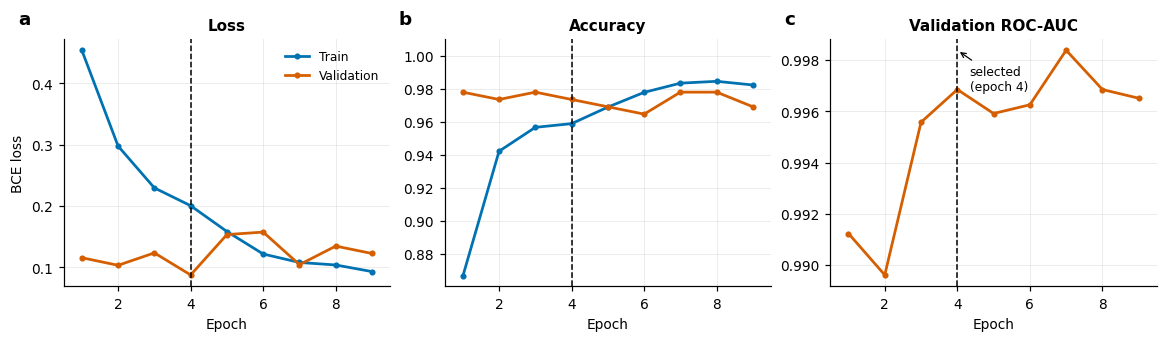

In [6]:
if history is not None:
    fig, ax = plt.subplots(1, 3, figsize=(10.5, 3))
    ax[0].plot(history.epoch, history.train_loss, 'o-', ms=3, color=C_INT, label='Train')
    ax[0].plot(history.epoch, history.val_loss, 'o-', ms=3, color=C_EXT, label='Validation')
    ax[0].set(title='Loss', xlabel='Epoch', ylabel='BCE loss')
    ax[1].plot(history.epoch, history.train_acc, 'o-', ms=3, color=C_INT, label='Train')
    ax[1].plot(history.epoch, history.val_acc, 'o-', ms=3, color=C_EXT, label='Validation')
    ax[1].set(title='Accuracy', xlabel='Epoch', ylim=(None, 1.01))
    ax[2].plot(history.epoch, history.val_auc, 'o-', ms=3, color=C_EXT)
    ax[2].set(title='Validation ROC-AUC', xlabel='Epoch')
    for a in ax:
        a.axvline(best_epoch, color='k', ls='--', lw=1)
        a.set_xlim(0.5, history.epoch.max() + .5)
    ax[0].legend()
    ax[2].annotate(f'selected\n(epoch {best_epoch})', (best_epoch, history.val_auc.max()), xytext=(8, -26),
                   textcoords='offset points', fontsize=8, arrowprops=dict(arrowstyle='->', lw=.8))
    for a, l in zip(ax, 'abc'):
        tag(a, l)
    save(fig, 'fig2_training_curves')
else:
    print('Released weights used; no training curves for this run.')

In [7]:
model.load_state_dict(torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True))


@torch.no_grad()
def collect_logits(loader):
    model.eval()
    logits, targets = [], []
    for x, t, _ in loader:
        logit, _ = model(x.to(DEVICE, non_blocking=True))
        logits.append(logit.float().cpu())
        targets.append(t)
    return torch.cat(logits), torch.cat(targets)


# temperature scaling, fitted on ORBSCAN validation only
val_logits, val_targets = collect_logits(val_loader)
nll_before = F.binary_cross_entropy_with_logits(val_logits, val_targets).item()
log_t = torch.zeros(1, requires_grad=True)
lbfgs = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)


def closure():
    lbfgs.zero_grad()
    loss_ = F.binary_cross_entropy_with_logits(val_logits / log_t.exp(), val_targets)
    loss_.backward()
    return loss_


if USE_TEMPERATURE_SCALING:
    lbfgs.step(closure)
    TEMPERATURE = float(log_t.exp().item())
nll_after = F.binary_cross_entropy_with_logits(val_logits / TEMPERATURE, val_targets).item()
print(f'Temperature {TEMPERATURE:.3f} | validation NLL {nll_before:.4f} -> {nll_after:.4f}')


def sens_spec(yt, yp, t):
    return recall_score(yt, yp >= t), recall_score(1 - yt, yp < t)


vy, vp, _ = predict(val_loader)
ts = np.linspace(.05, .95, 181)
val_curve = np.array([sens_spec(vy, vp, t) for t in ts])
youden = val_curve.sum(1) - 1
youden_t = ts[np.argmax(youden)]
ok = np.flatnonzero(val_curve[:, 0] >= MIN_SENSITIVITY)
edge_t = ts[ok[np.argmax(val_curve[ok, 1])]] if len(ok) else ts[np.argmax(val_curve[:, 0])]
plat = (val_curve[:, 0] >= MIN_SENSITIVITY) & (youden >= youden.max() - PLATEAU_TOL)
if not plat.any():
    plat = youden >= youden.max() - PLATEAU_TOL
logit = lambda q: np.log(q / (1 - q))
plateau_t = float(1 / (1 + np.exp(-(logit(ts[plat].min()) + logit(ts[plat].max())) / 2)))


def screening_threshold(floor):
    """Sensitivity-first: among thresholds reaching the validation sensitivity floor, take those within
    SPEC_TOL of the best specificity and use their centre (logit scale), away from both cliffs."""
    ok = val_curve[:, 0] >= floor
    if not ok.any():
        ok = val_curve[:, 0] >= val_curve[:, 0].max()
    keep = ok & (val_curve[:, 1] >= val_curve[ok, 1].max() - SPEC_TOL)
    return float(1 / (1 + np.exp(-(logit(ts[keep].min()) + logit(ts[keep].max())) / 2)))


screening_t = screening_threshold(MIN_SENSITIVITY)
OP_THRESHOLD = {'edge': edge_t, 'plateau': plateau_t, 'screening': screening_t}[THRESHOLD_RULE]

rules = {"Youden's J": youden_t, 'Edge (old rule)': edge_t, 'Plateau centre': plateau_t,
         f'Screening, floor {MIN_SENSITIVITY:.2f}': screening_t}
used = [k for k, v in rules.items() if v == OP_THRESHOLD][-1]
display(pd.DataFrame({'rule': [r + (' (used)' if r == used else '') for r in rules],
                      'threshold': list(rules.values()),
                      'val sensitivity': [sens_spec(vy, vp, t)[0] for t in rules.values()],
                      'val specificity': [sens_spec(vy, vp, t)[1] for t in rules.values()]}
                     ).style.format('{:.3f}', subset=['threshold', 'val sensitivity', 'val specificity']).hide(axis='index'))

# what each sensitivity floor would cost, judged on validation only
floor_rows = []
for fl in (0.90, 0.95, 0.97, 0.98, 0.99):
    t_ = screening_threshold(fl)
    floor_rows.append({'sensitivity floor': fl, 'threshold': t_, 'val sensitivity': sens_spec(vy, vp, t_)[0],
                       'val specificity': sens_spec(vy, vp, t_)[1]})
display(pd.DataFrame(floor_rows).style.format('{:.3f}').hide(axis='index'))

y, p, attention = predict(test_loader)
external_y, external_p, external_attention = predict(external_loader)
internal_groups = test_df.patient_id.values

Temperature 1.543 | validation NLL 0.0875 -> 0.0717


rule,threshold,val sensitivity,val specificity
Youden's J,0.785,0.951,1.000
Edge (old rule),0.785,0.951,1.000
Plateau centre,0.476,0.951,0.986
"Screening, floor 0.95 (used)",0.808,0.951,1.000


sensitivity floor,threshold,val sensitivity,val specificity
0.900,0.822,0.951,1.000
0.950,0.808,0.951,1.000
0.970,0.091,0.975,0.966
0.980,0.091,0.975,0.966
0.990,0.091,0.975,0.966


In [8]:
METRICS = ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'mcc', 'kappa', 'roc_auc', 'average_precision']


def metrics_at(yt, yp, t):
    pred = yp >= t
    tp, fp = np.sum(pred & (yt == 1)), np.sum(pred & (yt == 0))
    tn, fn = np.sum(~pred & (yt == 0)), np.sum(~pred & (yt == 1))
    n = len(yt)
    sens, spec, prec = tp / max(tp + fn, 1), tn / max(tn + fp, 1), tp / max(tp + fp, 1)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    pe = ((tp + fp) * (tp + fn) + (tn + fn) * (tn + fp)) / n ** 2
    return {'accuracy': (tp + tn) / n, 'precision': prec, 'sensitivity': sens, 'specificity': spec,
            'f1': 2 * prec * sens / max(prec + sens, 1e-12),
            'mcc': (tp * tn - fp * fn) / denom if denom else 0.0,
            'kappa': ((tp + tn) / n - pe) / (1 - pe) if pe < 1 else 0.0,
            'roc_auc': roc_auc_score(yt, yp), 'average_precision': average_precision_score(yt, yp)}


def bootstrap(yt, yp, t, groups=None, n=N_BOOTSTRAP, seed=SEED):
    """Percentile bootstrap; resamples patients (not eyes) when groups are given."""
    rng = np.random.RandomState(seed)
    if groups is not None:
        members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    rows = []
    while len(rows) < n:
        if groups is None:
            idx = rng.randint(0, len(yt), len(yt))
        else:
            idx = np.concatenate([members[i] for i in rng.randint(0, len(members), len(members))])
        if len(np.unique(yt[idx])) == 2:
            rows.append(metrics_at(yt[idx], yp[idx], t))
    return pd.DataFrame(rows)


cohorts = {'Internal ORBSCAN': (y, p, internal_groups), 'External Pentacam': (external_y, external_p, None)}
point, boot = {}, {}
for name, (yt, yp, g) in cohorts.items():
    point[name] = metrics_at(yt, yp, OP_THRESHOLD)
    boot[name] = bootstrap(yt, yp, OP_THRESHOLD, g)

ci = {n: {m: np.percentile(boot[n][m], [2.5, 97.5]) for m in METRICS} for n in cohorts}
table = pd.DataFrame({n: [f'{point[n][m]:.3f} [{ci[n][m][0]:.3f}, {ci[n][m][1]:.3f}]' for m in METRICS]
                      for n in cohorts}, index=METRICS)
table.loc['cases'] = [len(c[0]) for c in cohorts.values()]
display(table.loc[['cases'] + METRICS].style)
table.to_csv(WORK / 'overall_test_performance.csv')

pd.DataFrame({'patient_id': test_df.patient_id, 'eye': test_df.eye, 'label': y, 'p_keratoconus': p,
              'prediction': (p >= OP_THRESHOLD).astype(int)}).to_csv(WORK / 'test_predictions.csv', index=False)
pd.DataFrame({'patient_id': external_df.patient_id, 'eye': external_df.eye, 'label': external_y,
              'p_keratoconus': external_p, 'prediction': (external_p >= OP_THRESHOLD).astype(int)}
             ).to_csv(WORK / 'external_pentacam_predictions.csv', index=False)

,Internal ORBSCAN,External Pentacam
cases,282,395
accuracy,"0.986 [0.971, 0.997]","0.954 [0.934, 0.975]"
precision,"1.000 [1.000, 1.000]","0.995 [0.983, 1.000]"
sensitivity,"0.959 [0.913, 0.991]","0.914 [0.874, 0.953]"
specificity,"1.000 [1.000, 1.000]","0.995 [0.984, 1.000]"
f1,"0.979 [0.955, 0.996]","0.953 [0.930, 0.974]"
mcc,"0.969 [0.935, 0.993]","0.912 [0.872, 0.950]"
kappa,"0.968 [0.933, 0.993]","0.909 [0.867, 0.949]"
roc_auc,"1.000 [0.999, 1.000]","0.993 [0.988, 0.997]"
average_precision,"1.000 [0.998, 1.000]","0.994 [0.989, 0.998]"


In [9]:
def delong(yt, yp):
    """AUC and its variance (DeLong et al. 1988, fast version of Sun & Xu 2014)."""
    pos, neg = yp[yt == 1], yp[yt == 0]
    m, n = len(pos), len(neg)

    def midrank(x):
        order = np.argsort(x); z = x[order]; r = np.zeros(len(x)); i = 0
        while i < len(x):
            j = i
            while j < len(x) and z[j] == z[i]:
                j += 1
            r[i:j] = 0.5 * (i + j - 1) + 1
            i = j
        out = np.empty(len(x)); out[order] = r
        return out

    tz, tx, ty = midrank(np.concatenate([pos, neg])), midrank(pos), midrank(neg)
    auc = (tz[:m].sum() - m * (m + 1) / 2) / (m * n)
    v10, v01 = (tz[:m] - tx) / n, 1 - (tz[m:] - ty) / m
    return auc, np.var(v10, ddof=1) / m + np.var(v01, ddof=1) / n


def clopper_pearson(k, n, alpha=.05):
    lo = stats.beta.ppf(alpha / 2, k, n - k + 1) if k > 0 else 0.0
    hi = stats.beta.ppf(1 - alpha / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi


def calibration_fit(yt, yp):
    z = np.log(np.clip(yp, 1e-6, 1 - 1e-6) / (1 - np.clip(yp, 1e-6, 1 - 1e-6))).reshape(-1, 1)
    lr = LogisticRegression(C=1e6).fit(z, yt)
    return lr.coef_[0, 0], lr.intercept_[0]


def ece(yt, yp, bins=10):
    idx = np.clip(np.digitize(yp, np.linspace(0, 1, bins + 1)[1:-1]), 0, bins - 1)
    return sum((idx == b).mean() * abs(yt[idx == b].mean() - yp[idx == b].mean()) for b in range(bins) if (idx == b).any())


rows, aucs = [], {}
for name, (yt, yp, _) in cohorts.items():
    auc, var = delong(yt, yp)
    aucs[name] = (auc, var)
    pred = yp >= OP_THRESHOLD
    k_sens, n_sens = int((pred & (yt == 1)).sum()), int((yt == 1).sum())
    k_spec, n_spec = int((~pred & (yt == 0)).sum()), int((yt == 0).sum())
    slope, intercept = calibration_fit(yt, yp)
    rows.append({
        'cohort': name,
        'AUC (DeLong 95% CI)': f'{auc:.3f} [{max(auc - 1.96 * np.sqrt(var), 0):.3f}, {min(auc + 1.96 * np.sqrt(var), 1):.3f}]',
        'Sensitivity (exact 95% CI)': '{:.3f} [{:.3f}, {:.3f}] ({}/{})'.format(k_sens / n_sens, *clopper_pearson(k_sens, n_sens), k_sens, n_sens),
        'Specificity (exact 95% CI)': '{:.3f} [{:.3f}, {:.3f}] ({}/{})'.format(k_spec / n_spec, *clopper_pearson(k_spec, n_spec), k_spec, n_spec),
        'Brier': brier_score_loss(yt, yp), 'ECE': ece(yt, yp), 'Cal. slope': slope, 'Cal. intercept': intercept,
    })
stat_table = pd.DataFrame(rows).set_index('cohort')
display(stat_table.style.format({'Brier': '{:.4f}', 'ECE': '{:.4f}', 'Cal. slope': '{:.2f}', 'Cal. intercept': '{:.2f}'}))

# internal vs external gap: bootstrap difference (external - internal), two-sided
gap = []
for m in ['accuracy', 'sensitivity', 'specificity', 'f1', 'roc_auc']:
    d = boot['External Pentacam'][m].values - boot['Internal ORBSCAN'][m].values
    pv = min(1.0, 2 * (min((d >= 0).sum(), (d <= 0).sum()) + 1) / (len(d) + 1))
    gap.append({'metric': m, 'external - internal': point['External Pentacam'][m] - point['Internal ORBSCAN'][m],
                '95% CI': f'[{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]', 'p (bootstrap)': pv})
(a1, v1), (a2, v2) = aucs['Internal ORBSCAN'], aucs['External Pentacam']
z = (a1 - a2) / np.sqrt(v1 + v2) if v1 + v2 > 0 else 0.0
print(f'DeLong test, internal vs external AUC: z = {z:.2f}, p = {2 * stats.norm.sf(abs(z)):.4f}')
display(pd.DataFrame(gap).style.format({'external - internal': '{:+.3f}', 'p (bootstrap)': '{:.4f}'}).hide(axis='index'))
stat_table.to_csv(WORK / 'statistical_validation.csv')

,AUC (DeLong 95% CI),Sensitivity (exact 95% CI),Specificity (exact 95% CI),Brier,ECE,Cal. slope,Cal. intercept
cohort,,,,,,,
Internal ORBSCAN,"1.000 [0.999, 1.000]","0.959 [0.899, 0.989] (94/98)","1.000 [0.980, 1.000] (184/184)",0.0051,0.0159,2.11,1.79
External Pentacam,"0.993 [0.989, 0.998]","0.914 [0.866, 0.949] (181/198)","0.995 [0.972, 1.000] (196/197)",0.0478,0.1087,2.20,-1.54


DeLong test, internal vs external AUC: z = 2.61, p = 0.0089


metric,external - internal,95% CI,p (bootstrap)
accuracy,-0.031,"[-0.055, -0.005]",0.0210
sensitivity,-0.045,"[-0.098, 0.017]",0.1369
specificity,-0.005,"[-0.016, 0.000]",0.7316
f1,-0.027,"[-0.055, 0.007]",0.1049
roc_auc,-0.006,"[-0.012, -0.002]",0.0020


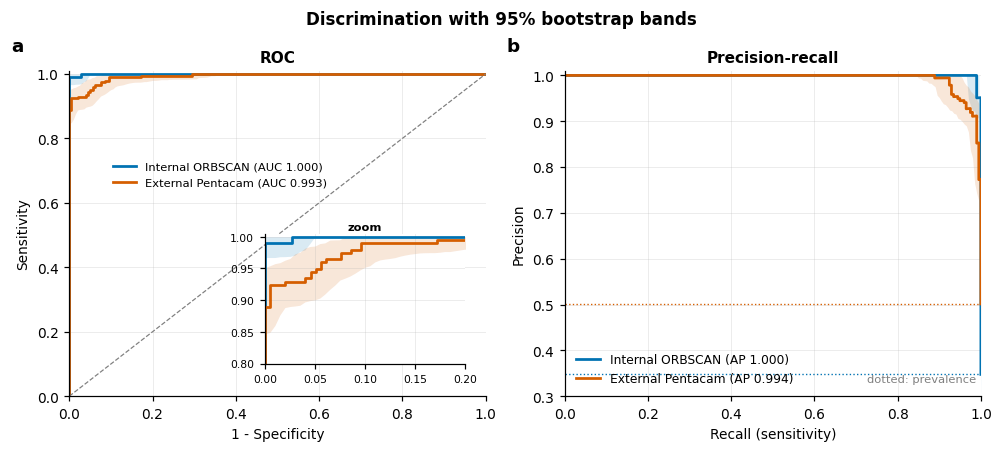

In [10]:
COLORS = {'Internal ORBSCAN': C_INT, 'External Pentacam': C_EXT}
grid = np.linspace(0, 1, 201)


def curve_band(yt, yp, groups, kind, n=500):
    rng = np.random.RandomState(SEED)
    members = [np.flatnonzero(groups == g) for g in np.unique(groups)] if groups is not None else None
    out = []
    while len(out) < n:
        idx = rng.randint(0, len(yt), len(yt)) if members is None else \
            np.concatenate([members[i] for i in rng.randint(0, len(members), len(members))])
        if len(np.unique(yt[idx])) < 2:
            continue
        if kind == 'roc':
            f, t_, _ = roc_curve(yt[idx], yp[idx])
            out.append(np.interp(grid, f, t_))
        else:
            pr, rc, _ = precision_recall_curve(yt[idx], yp[idx])
            out.append(np.interp(grid, rc[::-1], pr[::-1]))
    return np.percentile(out, [2.5, 97.5], axis=0)


fig, ax = plt.subplots(1, 2, figsize=(9, 4))
zoom = ax[0].inset_axes([.47, .10, .48, .40])
for name, (yt, yp, g) in cohorts.items():
    f, t_, _ = roc_curve(yt, yp)
    lo, hi = curve_band(yt, yp, g, 'roc')
    label = f'{name} (AUC {point[name]["roc_auc"]:.3f})'
    for a in (ax[0], zoom):
        a.plot(f, t_, color=COLORS[name], label=label if a is ax[0] else None)
        a.fill_between(grid, lo, hi, color=COLORS[name], alpha=.15, lw=0)
    pr, rc, _ = precision_recall_curve(yt, yp)
    lo, hi = curve_band(yt, yp, g, 'pr')
    ax[1].plot(rc, pr, color=COLORS[name], label=f'{name} (AP {point[name]["average_precision"]:.3f})')
    ax[1].fill_between(grid, lo, hi, color=COLORS[name], alpha=.15, lw=0)
    ax[1].axhline(yt.mean(), color=COLORS[name], ls=':', lw=.9)
ax[0].plot([0, 1], [0, 1], color='gray', ls='--', lw=.8)
ax[0].set(xlabel='1 - Specificity', ylabel='Sensitivity', title='ROC', xlim=(0, 1), ylim=(0, 1.01))
ax[0].legend(loc='center left', bbox_to_anchor=(0.08, .68), fontsize=7.5)
zoom.set(xlim=(0, .2), ylim=(.8, 1.005))
zoom.grid(alpha=.25); zoom.tick_params(labelsize=7); zoom.set_title('zoom', fontsize=7.5, pad=2)
ax[1].set(xlabel='Recall (sensitivity)', ylabel='Precision', title='Precision-recall', xlim=(0, 1), ylim=(.3, 1.01))
ax[1].legend(loc='lower left')
ax[1].text(.99, .33, 'dotted: prevalence', ha='right', fontsize=7.5, color='gray')
for a, l in zip(ax, 'ab'):
    tag(a, l)
fig.suptitle('Discrimination with 95% bootstrap bands', fontsize=11, fontweight='bold')
save(fig, 'fig3_roc_and_precision_recall')

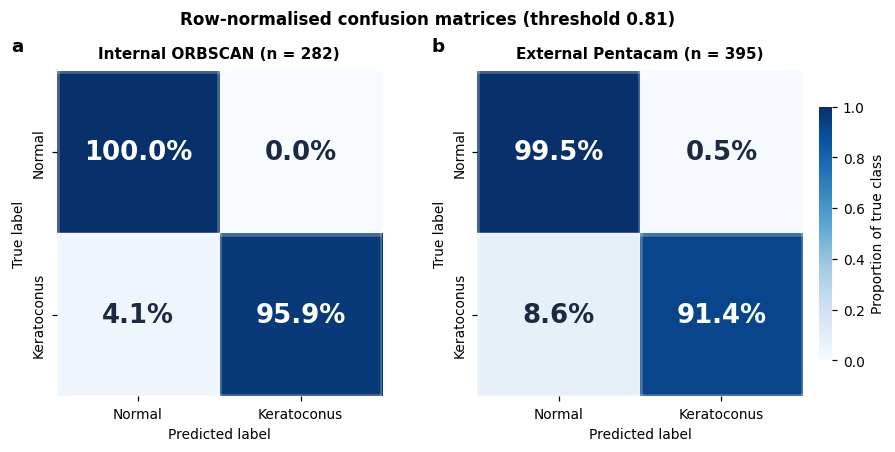

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(8.4, 4.0))
for a, (name, (yt, yp, _)) in zip(ax, cohorts.items()):
    cm = confusion_matrix(yt, (yp >= OP_THRESHOLD).astype(int), labels=[0, 1])
    pct = cm / cm.sum(1, keepdims=True)
    im = a.imshow(pct, cmap='Blues', vmin=0, vmax=1, aspect='equal')
    a.set_xticks(np.arange(-.5, 2, 1), minor=True); a.set_yticks(np.arange(-.5, 2, 1), minor=True)
    a.grid(which='minor', color='white', lw=3); a.grid(which='major', visible=False)
    a.tick_params(which='minor', length=0)
    for r in range(2):
        for c in range(2):
            a.text(c, r, f'{100 * pct[r, c]:.1f}%', ha='center', va='center', fontsize=17, fontweight='bold',
                   color='white' if pct[r, c] > .5 else '#1b2a41')
    a.set_xticks([0, 1]); a.set_yticks([0, 1])
    a.set_xticklabels(CLASS_NAMES); a.set_yticklabels(CLASS_NAMES, rotation=90, va='center')
    a.set_xlabel('Predicted label'); a.set_ylabel('True label')
    a.set_title(f'{name} (n = {len(yt)})', pad=8)
    for s_ in a.spines.values():
        s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=.78, pad=.02)
cb.set_label('Proportion of true class'); cb.outline.set_visible(False); cb.ax.grid(False)
tag(ax[0], 'a'); tag(ax[1], 'b')
fig.suptitle(f'Row-normalised confusion matrices (threshold {OP_THRESHOLD:.2f})', fontsize=11, fontweight='bold')
save(fig, 'fig4_confusion_matrices')

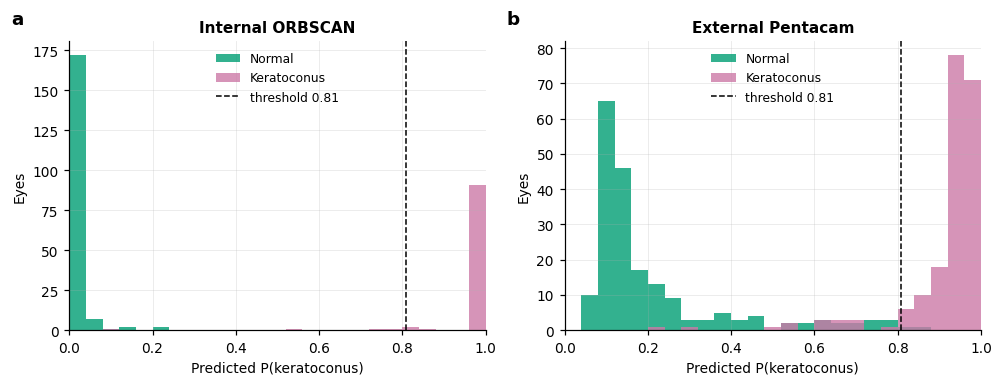

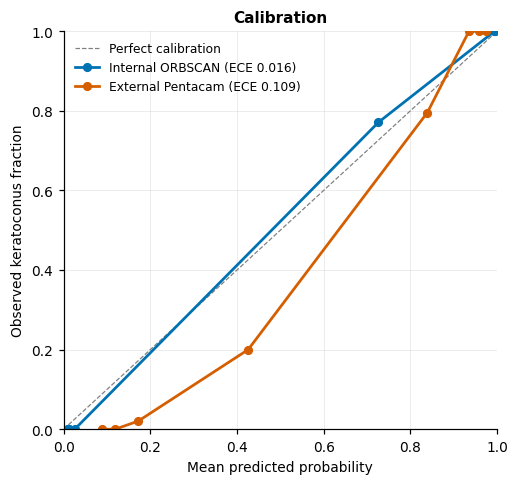

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
bins = np.linspace(0, 1, 26)
for a, (name, (yt, yp, _)), l in zip(ax, cohorts.items(), 'ab'):
    for c in (0, 1):
        a.hist(yp[yt == c], bins=bins, color=C_CLASS[c], alpha=.8, label=CLASS_NAMES[c])
    a.axvline(OP_THRESHOLD, color='k', ls='--', lw=1, label=f'threshold {OP_THRESHOLD:.2f}')
    a.set(xlabel='Predicted P(keratoconus)', ylabel='Eyes', title=name, xlim=(0, 1))
    a.legend(loc='upper center')
    tag(a, l)
save(fig, 'fig5_score_distributions')

fig, ax = plt.subplots(figsize=(4.6, 4.3))
ax.plot([0, 1], [0, 1], color='gray', ls='--', lw=.8, label='Perfect calibration')
for name, (yt, yp, _) in cohorts.items():
    frac, mean_p = calibration_curve(yt, yp, n_bins=8, strategy='quantile')
    ax.plot(mean_p, frac, 'o-', ms=5, color=COLORS[name], label=f'{name} (ECE {ece(yt, yp):.3f})')
ax.set(xlabel='Mean predicted probability', ylabel='Observed keratoconus fraction', title='Calibration', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='upper left')
save(fig, 'fig6_calibration')

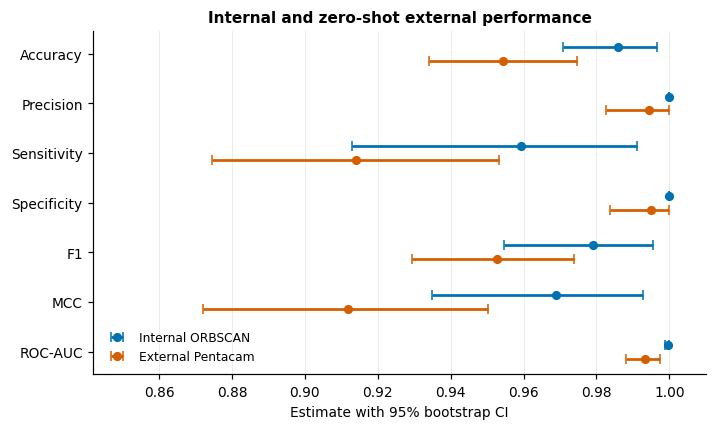

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
shown = ['accuracy', 'precision', 'sensitivity', 'specificity', 'f1', 'mcc', 'roc_auc']
ypos = np.arange(len(shown))[::-1]
for k, (name, col) in enumerate(COLORS.items()):
    est = np.array([point[name][m] for m in shown])
    lo = est - np.array([ci[name][m][0] for m in shown])
    hi = np.array([ci[name][m][1] for m in shown]) - est
    ax.errorbar(est, ypos + (.14 if k == 0 else -.14), xerr=[lo, hi], fmt='o', ms=5, capsize=3, color=col, label=name)
ax.set_yticks(ypos)
ax.set_yticklabels(['Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'MCC', 'ROC-AUC'])
ax.set(xlabel='Estimate with 95% bootstrap CI', title='Internal and zero-shot external performance', xlim=(max(0, min(ci[n][m][0] for n in COLORS for m in shown) - .03), 1.01))
ax.grid(axis='y', alpha=0)
ax.legend(loc='lower left')
save(fig, 'fig7_performance_forest')

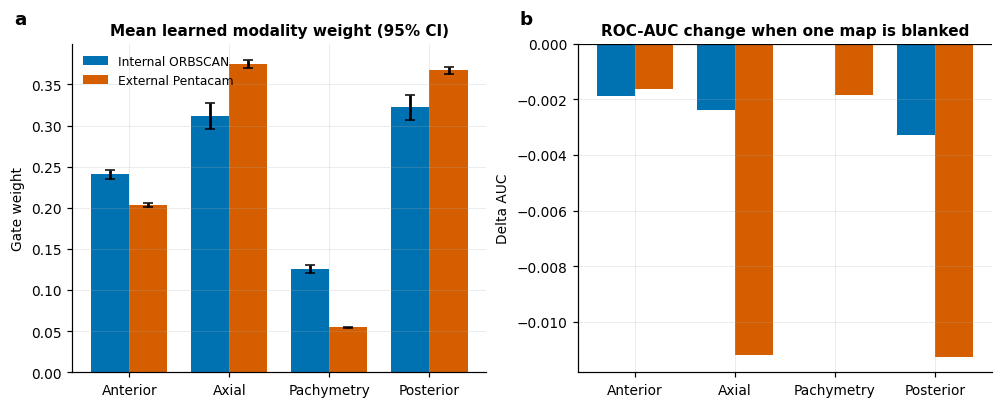

,Internal ORBSCAN,External Pentacam
Anterior,-0.0019,-0.0016
Axial,-0.0024,-0.0112
Pachymetry,-0.0001,-0.0018
Posterior,-0.0033,-0.0113


In [14]:
@torch.no_grad()
def predict_without(loader, drop):
    model.eval()
    out = []
    for x, _, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        x[:, drop] = 0
        out.append(torch.sigmoid(model(x)[0].float() / TEMPERATURE).cpu().numpy())
    return np.concatenate(out)


ablation = {}
for name, loader, (yt, yp, _) in ((n, l, cohorts[n]) for n, l in (('Internal ORBSCAN', test_loader), ('External Pentacam', external_loader))):
    ablation[name] = [roc_auc_score(yt, predict_without(loader, i)) - roc_auc_score(yt, yp) for i in range(len(MODALITIES))]

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
att = {'Internal ORBSCAN': (attention, y), 'External Pentacam': (external_attention, external_y)}
w = .38
x_pos = np.arange(len(MODALITIES))
for k, (name, (a_, yt)) in enumerate(att.items()):
    mean, sem = a_.mean(0), a_.std(0, ddof=1) / np.sqrt(len(a_))
    ax[0].bar(x_pos + (k - .5) * w, mean, w, yerr=1.96 * sem, color=COLORS[name], capsize=3, label=name)
    ax[1].bar(x_pos + (k - .5) * w, ablation[name], w, color=COLORS[name], label=name)
ax[0].set(title='Mean learned modality weight (95% CI)', ylabel='Gate weight')
ax[1].set(title='ROC-AUC change when one map is blanked', ylabel='Delta AUC')
ax[1].axhline(0, color='k', lw=.8)
for a, l in zip(ax, 'ab'):
    a.set_xticks(x_pos)
    a.set_xticklabels([m.title() for m in MODALITIES])
    tag(a, l)
ax[0].legend()
save(fig, 'fig8_modality_attention_and_ablation')
display(pd.DataFrame(ablation, index=[m.title() for m in MODALITIES]).style.format('{:+.4f}'))

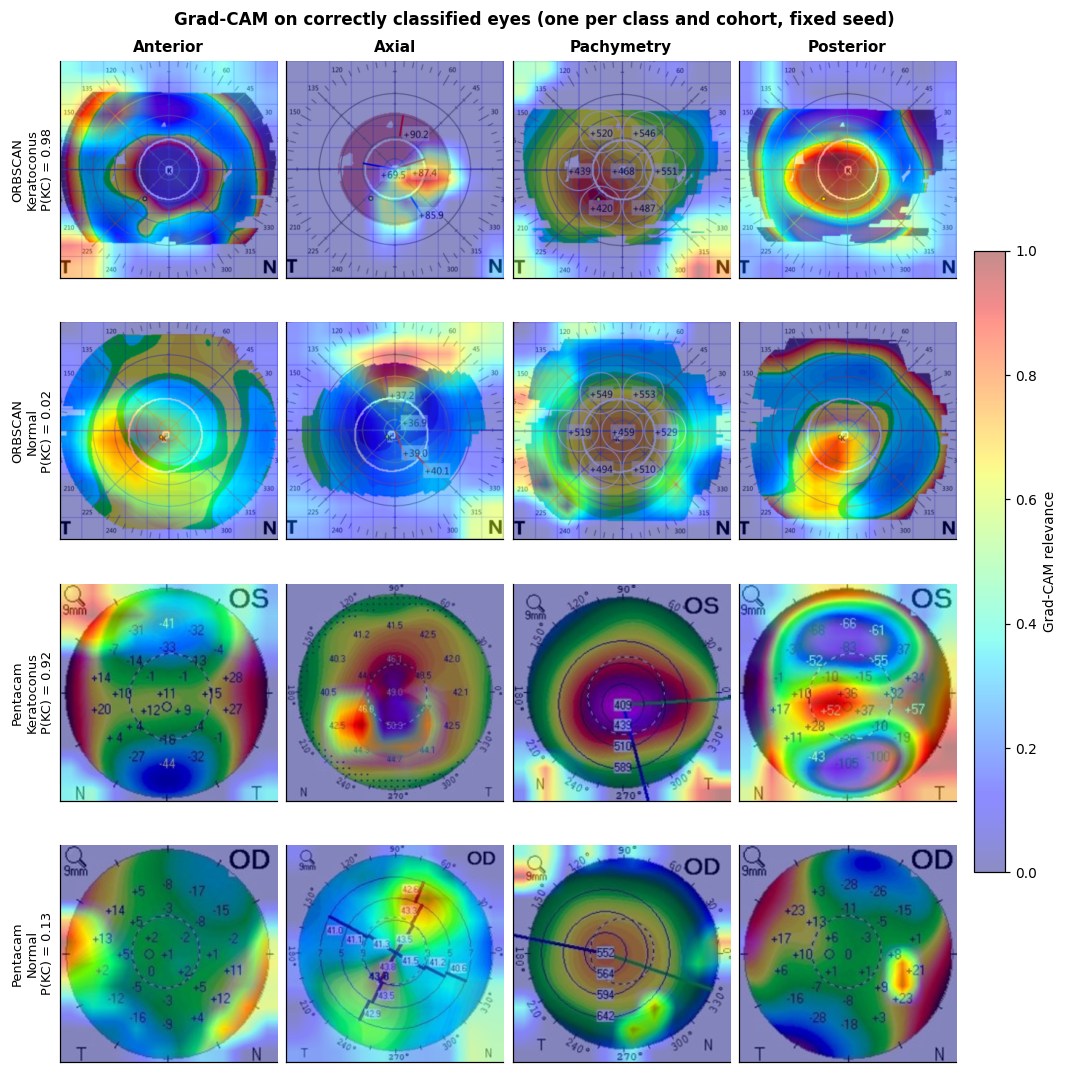

In [15]:
MEAN, STD = np.array([.485, .456, .406]), np.array([.229, .224, .225])


def gradcam(x, target):
    acts, grads, hooks = {}, {}, []
    for i in range(len(MODALITIES)):
        layer = model.enc[i].features[-1]
        hooks.append(layer.register_forward_hook(lambda m, inp, out, i=i: acts.__setitem__(i, out.detach())))
        hooks.append(layer.register_full_backward_hook(lambda m, gi, go, i=i: grads.__setitem__(i, go[0].detach())))
    model.zero_grad(set_to_none=True)
    score, _ = model(x)
    (score[0] if target == 1 else -score[0]).backward()
    for h in hooks:
        h.remove()
    cams = []
    for i in range(len(MODALITIES)):
        cam = F.relu((grads[i].mean(dim=(2, 3), keepdim=True) * acts[i]).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)[0, 0].cpu().numpy()
        cams.append((cam - cam.min()) / (cam.max() - cam.min() + 1e-8))
    return cams


def pick(yt, yp, cls, rng):
    hit = np.flatnonzero((yt == cls) & ((yp >= OP_THRESHOLD) == bool(cls)))     # correctly classified
    if len(hit):
        return int(rng.choice(hit))
    pool = np.flatnonzero(yt == cls)                                           # none correct: show the most confident
    return int(pool[np.argmax(yp[pool] if cls else -yp[pool])])


rng = np.random.RandomState(SEED)
cases = []
for name, frame, root, (yt, yp, _) in (('ORBSCAN', test_df, ROOT, cohorts['Internal ORBSCAN']),
                                       ('Pentacam', external_df, EXTERNAL_ROOT, cohorts['External Pentacam'])):
    for cls in (1, 0):
        cases.append((name, frame, root, pick(yt, yp, cls, rng), yp))

fig, ax = plt.subplots(len(cases), len(MODALITIES), figsize=(9.6, 2.45 * len(cases)))
for r, (name, frame, root, idx, yp) in enumerate(cases):
    row = frame.iloc[idx]
    with torch.no_grad():
        x = torch.stack([eval_tf(Image.open(Path(root) / row[f'{m}_path']).convert('RGB')) for m in MODALITIES]).unsqueeze(0).to(DEVICE)
    model.eval()
    cams = gradcam(x, int(row.label))
    for c, m in enumerate(MODALITIES):
        img = np.clip(x[0, c].cpu().permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)
        ax[r, c].imshow(img)
        im = ax[r, c].imshow(cams[c], cmap='jet', alpha=.45, vmin=0, vmax=1)
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([]); ax[r, c].grid(False)
        if r == 0:
            ax[r, c].set_title(m.title(), fontweight='bold')
    ax[r, 0].set_ylabel(f'{name}\n{CLASS_NAMES[int(row.label)]}\nP(KC) = {yp[idx]:.2f}', fontsize=8.5)
fig.colorbar(im, ax=ax, shrink=.6, pad=.02, label='Grad-CAM relevance')
fig.suptitle('Grad-CAM on correctly classified eyes (one per class and cohort, fixed seed)', fontsize=11, fontweight='bold')
save(fig, 'fig9_gradcam')

In [16]:
# per-seed record: change SEED in the setup cell and rerun to add a seed; report the mean +/- std
shutil.copy(CHECKPOINT, WORK / f'best_model_seed{SEED}.pt')
if not (WORK / RELEASED_WEIGHTS_NAME).exists():
    shutil.copy(CHECKPOINT, WORK / RELEASED_WEIGHTS_NAME)

row = {'seed': SEED, 'threshold': OP_THRESHOLD}
for tag_, name in (('int', 'Internal ORBSCAN'), ('ext', 'External Pentacam')):
    row.update({f'{tag_}_{m}': point[name][m] for m in METRICS})
csv = WORK / 'seed_results.csv'
runs = pd.read_csv(csv) if csv.exists() else pd.DataFrame(columns=['seed'])
runs = pd.concat([runs[runs.seed != SEED], pd.DataFrame([row])], ignore_index=True).sort_values('seed')
runs.to_csv(csv, index=False)
display(runs.round(4))
if len(runs) > 1:
    display(runs.drop(columns=['seed', 'threshold']).agg(['mean', 'std']).round(4))

digest = hashlib.sha256(open(CHECKPOINT, 'rb').read()).hexdigest()
print('SHA-256 of evaluated weights:', digest)

files = sorted(FIG_DIR.glob('*'))
with zipfile.ZipFile(WORK / 'figures.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in files:
        z.write(f, arcname=f.name)
print(f'{len(files)} figure files zipped to {WORK / "figures.zip"}')

,seed,threshold,int_accuracy,int_precision,int_sensitivity,int_specificity,int_f1,int_mcc,int_kappa,int_roc_auc,int_average_precision,ext_accuracy,ext_precision,ext_sensitivity,ext_specificity,ext_f1,ext_mcc,ext_kappa,ext_roc_auc,ext_average_precision
0,42,0.8078,0.9858,1.0,0.9592,1.0,0.9792,0.9689,0.9684,0.9997,0.9995,0.9544,0.9945,0.9141,0.9949,0.9526,0.9119,0.9089,0.9934,0.994


SHA-256 of evaluated weights: 46ff0eea420359fc308835d68c9f4a20915edefdf0d7828857f3ed1308b2d568
18 figure files zipped to /kaggle/working/figures.zip
